In [20]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector, SparsePauliOp
import numpy as np
import matplotlib.pyplot as plt


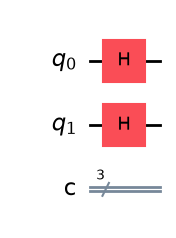

In [21]:
qc = QuantumCircuit(2,3)
qc.h(0)
qc.h(1)
qc.draw(output='mpl', filename='circuit.png')

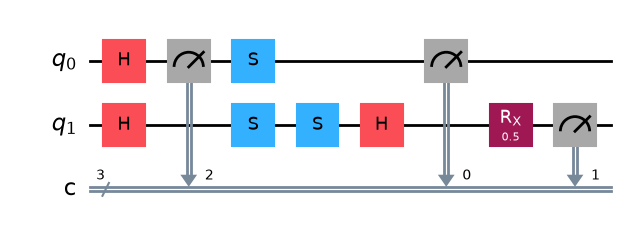

In [22]:
def build(D_1,D_2):
    qc = QuantumCircuit(2,3)
    qc.h(0)
    qc.h(1)
    
    for i,op in [(0,D_1),(1,D_2)]:
        if op == 'I':
            qc.id(i)
        elif op == 'Z':
            qc.z(i)
        elif op == 'S':
            qc.s(i)
        elif op == 'Sdg':
            qc.sdg(i)
        elif op == 'M':
            qc.measure(i,2)
        else:
            raise ValueError(f"Invalid operator: {op}")

    qc.s(0)
    qc.s(1)
    qc.h(1)
    qc.rx(0.5,1)
    qc.measure(0,0)
    qc.measure(1,1)
    return qc

a= build("M", "S")
a.draw(output='mpl', filename='circuit.png')

I ⊗ I   weight +0.5


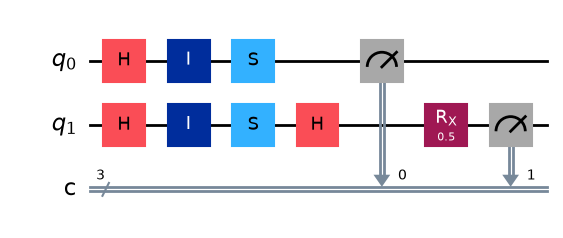

Z ⊗ Z   weight +0.5


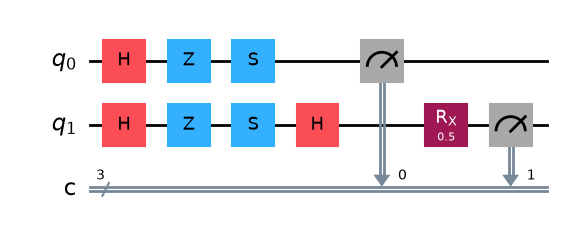

M ⊗ S   weight -0.5


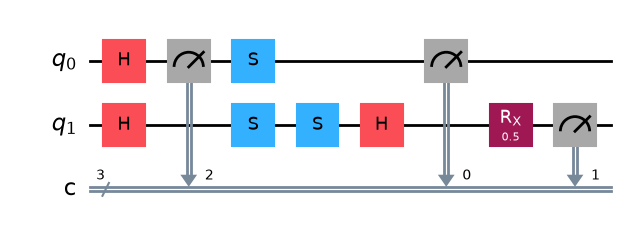

M ⊗ Sdg   weight +0.5


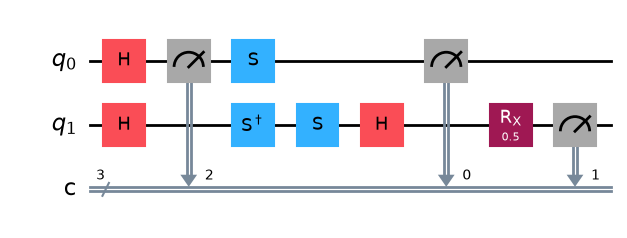

S ⊗ M   weight -0.5


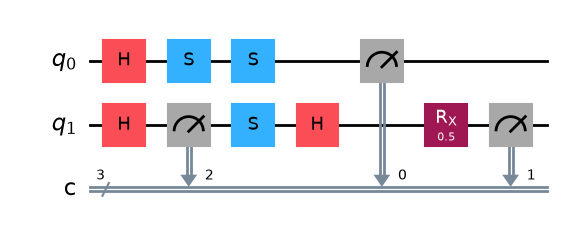

Sdg ⊗ M   weight +0.5


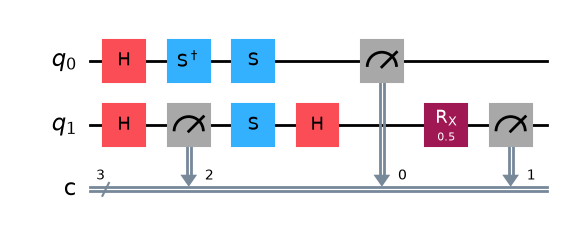

In [23]:
terms = [
    ("I",   "I",   +0.5),
    ("Z",   "Z",   +0.5),
    ("M",   "S",   -0.5),
    ("M",   "Sdg", +0.5),
    ("S",   "M",   -0.5),
    ("Sdg", "M",   +0.5),
]

circuits = [build(d1, d2) for d1, d2, w in terms]

for (d1, d2, w), qc in zip(terms, circuits):
    print(f"{d1} ⊗ {d2}   weight {w:+}")
    display(qc.draw(output='mpl'))

In [24]:
sim = AerSimulator()
Simulation = sim.run(circuits, shots=1024).result()
print(Simulation.get_counts(circuits[0]))

{'011': 379, '000': 153, '010': 360, '001': 132}


In [25]:
sim = AerSimulator()
shots = 4096

all_counts = []
for (d1, d2, w), qc in zip(terms, circuits):
    counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()
    all_counts.append(counts)
    print(f"{d1} ⊗ {d2}:", counts)

I ⊗ I: {'011': 1538, '010': 1536, '001': 516, '000': 506}
Z ⊗ Z: {'000': 1492, '001': 1520, '010': 577, '011': 507}
M ⊗ S: {'111': 1866, '010': 1962, '000': 136, '101': 132}
M ⊗ Sdg: {'101': 1977, '000': 1873, '111': 104, '010': 142}
S ⊗ M: {'101': 491, '001': 503, '100': 535, '110': 519, '000': 522, '010': 477, '011': 549, '111': 500}
Sdg ⊗ M: {'110': 537, '001': 463, '111': 513, '011': 516, '100': 512, '101': 522, '010': 492, '000': 541}


In [32]:
def value(counts,shots):
    total = 0
    for bits,n in counts.items():
        mid = int(bits[0])
        q1 = int(bits[1])
        q2 = int(bits[2])
        zz = (-1)**(q1+q2)
        sign = (-1)**mid

        total += zz*sign*n
    return total/shots

for (d1, d2, w), counts in zip(terms, all_counts):
    print(f"{d1} ⊗ {d2}:  value = {value(counts, shots):+.3f}")


I ⊗ I:  value = -0.002
Z ⊗ Z:  value = -0.024
M ⊗ S:  value = -0.869
M ⊗ Sdg:  value = +0.880
S ⊗ M:  value = +0.016
Sdg ⊗ M:  value = +0.033


In [33]:
cut_value = 0
for (d1, d2, w), counts in zip(terms, all_counts):
    cut_value += w * value(counts, shots)

# Exact answer from the original circuit with a real CNOT
ref = QuantumCircuit(2)
ref.h(0)
ref.cx(0, 1)
ref.rx(0.5, 1)
exact_value = Statevector(ref).expectation_value(SparsePauliOp("ZZ")).real

print("Hand-built cut:", cut_value)
print("Exact:         ", exact_value)
print("Error:         ", abs(cut_value - exact_value))

Hand-built cut: 0.8701171875
Exact:          0.8775825618903725
Error:          0.007465374390372537
